# Imports and Reading data

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 200)

In [ ]:
df = pd.read_csv('OTO-ESC-200k.csv')

# Data understanding

In [ ]:
df.shape

# Check the number of rows and columns.

In [ ]:
df.head(5)

In [ ]:
df.dtypes

# Data preparation

In [ ]:
df.isna().sum()

# Check missing values and duplicate rows before analysis.

# Feature understanding

In [ ]:
cv = df['converged'].value_counts().head(10).plot(kind = 'bar', title = 'Convergence count')

cv.set_xlabel('Converged')
cv.set_ylabel('Counts')

# More than 70% converged. I think this is a healthy spread as we care more about the converged combinations

In [ ]:
ct = df['convergence_time'].plot(kind = 'kde',
                title = 'Convergence time count')
ct.set_xlabel('Convergence time')
ct.set_ylabel('Frequency')

# Many combinations lead to convergence time < 12.5 seconds, which is really impressive

In [ ]:
sum(df['convergence_time'] < 10)

# There are 1560 out of 200000 combinations that has the convergence_time < 10, which is extremely good

In [ ]:
sum(df['convergence_time'] < 5)

# 259 combinations have convergence time < 5. I see potential.


# Feature relationships

In [ ]:
parameter_columns = ['optimizer_gain', 'dither_amplitude', 'dither_frequency', 'r_ideal_0', 'lambda_r_ideal']
for i in parameter_columns:
    df.plot(kind = 'scatter',
            x = i,
            y = 'convergence_time')
    plt.show()


In [ ]:
sns.pairplot(df,
             vars = parameter_columns + ['convergence_time'])
plt.show()


In [ ]:
sns.heatmap(df.drop(columns = ['converged', 'convergence_time', 'energy_max']).corr(), annot = True)


In [ ]:
dfcut = df[df['convergence_time'] < 10]
for i in parameter_columns:
    dfcut.plot(kind = 'scatter',
            x = i,
            y = 'convergence_time')
    plt.show()


In [ ]:
sns.pairplot(dfcut,
             vars = parameter_columns + ['convergence_time'])
plt.show()


In [ ]:
sns.heatmap(dfcut.drop(columns = ['converged', 'convergence_time', 'energy_max']).corr(), annot = True)


I think it would be useful to plot a 3d plot to visualize where the false predictions are.

# Visualization

In [ ]:
import plotly.express as px

In [ ]:
fig200k = px.scatter_3d(df,
                    x = 'optimizer_gain',
                    y = 'dither_amplitude',
                    z = 'dither_frequency',
                    color = 'convergence_time',
                    title = '3D scatter',
                    labels = {'optimizer_gain' : 'Optimizer gain',
                              'dither_amplitude' : 'Dither amplitude',
                              'dither_frequency' : 'Dither Frequency'})
fig200k.update_traces(marker=dict(size=3))
fig200k.show()

In [ ]:
# Exporting the plot (put it comment as I would run the notebook all over every time I open)
# fig200k.write_html("3dscatter200k.html")

# Modelling: Classification

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

torch.manual_seed(1)  #reproducible weights and batch shuffling

In [ ]:
# Adding more features to the dataset
df['log10gain'] = np.log10(df['optimizer_gain'])
df['sinfre'] = np.sin(df['dither_frequency'])
df['product'] = df['optimizer_gain'] * df['dither_amplitude'] * df['sinfre']

In [ ]:
# Create training sets

X = df[parameter_columns + ['log10gain', 'sinfre', 'product']]
y = df['choose_ESC']

# Get 60% of the dataset as the training set. Put the remaining 40% in temporary variables: x_ and y_.
X_train, X_, y_train, y_ = train_test_split(X, y, test_size=0.40, random_state=1)

# Split the 40% subset above into two: one half for cross validation and the other for the test set
X_cv, X_test, y_cv, y_test = train_test_split(X_, y_, test_size=0.50, random_state=1)

# Delete temporary variables
del X_, y_

In [ ]:
# Convert to float32 tensors
Xtr = torch.tensor(X_train.values, dtype=torch.float32)
ytr = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
Xcv = torch.tensor(X_cv.values, dtype=torch.float32)
ycv = torch.tensor(y_cv.values, dtype=torch.float32).reshape(-1, 1)

# Mini-batches of 100, reshuffled every epoch
train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=100, shuffle=True)

In [ ]:
# Defining models

n = Xtr.shape[1]  #number of input features

model1 = nn.Sequential(
    nn.Linear(n, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 1)
)

model2 = nn.Sequential(
    nn.Linear(n, 64), nn.ReLU(),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 1)
)

In [ ]:
def train(model, epochs=300, lr=0.01):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'loss': [], 'val_loss': []}

    for epoch in range(epochs):
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            history['loss'].append(loss_fn(model(Xtr), ytr).item())
            history['val_loss'].append(loss_fn(model(Xcv), ycv).item())

    return history

def predict_logits(model, X):
    with torch.no_grad():
        return model(X)

In [ ]:
# Train with model 1

history1 = train(model1)
plt.plot(history1['loss'], label='train loss')
plt.plot(history1['val_loss'], label='cv loss')
plt.legend()
plt.show()

In [ ]:
logits1 = predict_logits(model1, Xcv)
probs1 = torch.sigmoid(logits1).numpy() # convert logit to probability
y_pred1 = (probs1 > 0.5).astype(int).flatten() # threshold at 0.5, flatten to 1D
accuracy1 = accuracy_score(y_cv, y_pred1)
print(f"CV accuracy: {accuracy1:.3f}")

In [ ]:
print(confusion_matrix(y_cv, y_pred1))
print(classification_report(y_cv, y_pred1))

In [ ]:
train_logits1 = predict_logits(model1, Xtr)
train_probs1 = torch.sigmoid(train_logits1).numpy()
train_pred1 = (train_probs1 > 0.5).astype(int).flatten()
train_acc1 = accuracy_score(y_train, train_pred1)
print(f"Train accuracy: {train_acc1:.3f}")

In [ ]:
# Train with model 2

history2 = train(model2)
plt.plot(history2['loss'], label='train loss')
plt.plot(history2['val_loss'], label='cv loss')
plt.legend()
plt.show()

In [ ]:
logits2 = predict_logits(model2, Xcv)
probs2 = torch.sigmoid(logits2).numpy() # convert logit to probability
y_pred2 = (probs2 > 0.5).astype(int).flatten() # threshold at 0.5, flatten to 1D
accuracy2 = accuracy_score(y_cv, y_pred2)
print(f"CV accuracy: {accuracy2:.3f}")

In [ ]:
print(confusion_matrix(y_cv, y_pred2))
print(classification_report(y_cv, y_pred2))

In [ ]:
train_logits2 = predict_logits(model2, Xtr)
train_probs2 = torch.sigmoid(train_logits2).numpy()
train_pred2 = (train_probs2 > 0.5).astype(int).flatten()
train_acc2 = accuracy_score(y_train, train_pred2)
print(f"Train accuracy: {train_acc2:.3f}")

I think there is still room for improvement, but we would have to analyse the wrong predictions first.

In [ ]:
# Find where the false positives are
false_positive1 = (y_pred1 == 1) & (y_cv == 0)
X_cv1_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv1_df[false_positive1].describe())

false_positive2 = (y_pred2 == 1) & (y_cv == 0)
X_cv2_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv2_df[false_positive2].describe())

In [ ]:
# Merge the false positives into 1 table

fp1 = X_cv1_df[false_positive1]
fp2 = X_cv2_df[false_positive2]

fp = pd.concat([fp1, fp2], ignore_index=True)
print(fp.describe())

In [ ]:
# Drop duplicated rows of fp

fp = fp.loc[~fp.duplicated()].reset_index(drop = True)
print(fp.describe())

In [ ]:
# Find where the false positives are
false_positive1 = (y_pred1 == 1) & (y_cv == 0)
X_cv1_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv1_df[false_positive1].describe())

false_positive2 = (y_pred2 == 1) & (y_cv == 0)
X_cv2_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv2_df[false_positive2].describe())

In [ ]:
# Merge the false positives into 1 table

fp1 = X_cv1_df[false_positive1]
fp2 = X_cv2_df[false_positive2]

fp = pd.concat([fp1, fp2], ignore_index=True)
print(fp.describe())

In [ ]:
# Drop duplicated rows of fp

fp = fp.loc[~fp.duplicated()].reset_index(drop = True)
print(fp.describe())

In [ ]:
# Find where the false negatives are
false_negative1 = (y_pred1 == 0) & (y_cv == 1)
X_cv1_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv1_df[false_negative1].describe())

false_negative2 = (y_pred2 == 0) & (y_cv == 1)
X_cv2_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv2_df[false_negative2].describe())

In [ ]:
# Merge the false negatives into 1 table

fn1 = X_cv1_df[false_negative1]
fn2 = X_cv2_df[false_negative2]

fn = pd.concat([fn1, fn2], ignore_index=True)
print(fn.describe())

In [ ]:
# Drop duplicated rows of fn

fn = fn.loc[~fn.duplicated()].reset_index(drop = True)
print(fn.describe())

I realized that I did not pay enough attention to thhe dither amplitude. 
I will generate another dataset with wider range of dither amplitude (and dither frequency) to hopefully get a symmetric 3d plot.
I need to increase the range of all 3 parameters.

# Averaged-ESC analysis (for the report)
Each run is summarised by two quantities computed from its ESC parameters:
- **averaged convergence rate** $\lambda_\mathrm{avg} = 2 n_\mathrm{ref}^2\, k\, c(\omega)$, where $c(\omega)$ is how much of the dither survives the plasma's low-pass response ($\bar\alpha \approx 0.594$ s$^{-1}$) and the high-pass filter. The predicted convergence time from $\hat r_0 = 0$ is $\ln 20/\lambda_\mathrm{avg}$.
- **predicted dither loss** $L_\mathrm{dith} = T\,\frac{n_\mathrm{ref}^2}{4}\,\frac{2a^2\bar\alpha^2}{\bar\alpha^2+\omega^2}$: the energy lost to the dither oscillation over a run.

Plots are drawn with matplotlib's default style (inside `plt.style.context`), so the global `ggplot` style of this notebook is not changed.

In [ ]:
# Helper functions for the averaged-ESC analysis (report, Sec. 3.2-3.3)
import numpy as np
import pandas as pd

N_REF = 11.5                              # total density reference [1e19 m^-3]
ALPHA_D, ALPHA_T = 1/1.71, 1/1.66         # loss rates [1/s]
ALPHA_BAR = 0.5 * (ALPHA_D + ALPHA_T)     # mean loss rate = plant corner frequency [1/s]
T_END = 100.0                             # run length [s]

def c_factor(f):
    """Effective gradient gain c(w) = |G H| cos(phi) seen by the demodulator.
    G(s) = abar/(s+abar): D/T split response to r;  H(s) = s/(s+w/pi): high-pass filter."""
    w = 2 * np.pi * np.asarray(f, dtype=float)
    phi = -np.arctan(w / ALPHA_BAR) + np.arctan(1 / np.pi)
    mag = ALPHA_BAR / np.sqrt(ALPHA_BAR**2 + w**2) / np.sqrt(1 + 1 / np.pi**2)
    return mag * np.cos(phi)

def lam_avg(k, f):
    """Averaged ESC convergence rate [1/s]: d(r_hat)/dt = -lam_avg * (r_hat - r_ideal)."""
    return 2 * N_REF**2 * np.asarray(k, dtype=float) * c_factor(f)

def dither_loss(a, f, T=T_END):
    """Predicted energy lost to the dither over a run of length T (energy units)."""
    w = 2 * np.pi * np.asarray(f, dtype=float)
    a = np.asarray(a, dtype=float)
    return T * N_REF**2 / 4 * 2 * a**2 * ALPHA_BAR**2 / (ALPHA_BAR**2 + w**2)

def panel_letter(ax, letter):
    ax.text(-0.12, 1.06, letter, transform=ax.transAxes, fontsize=11, fontweight='bold', va='bottom', ha='right')

FOC, GR = '#1f5fa8', '#8a8a8a'   # colours: ESC / secondary

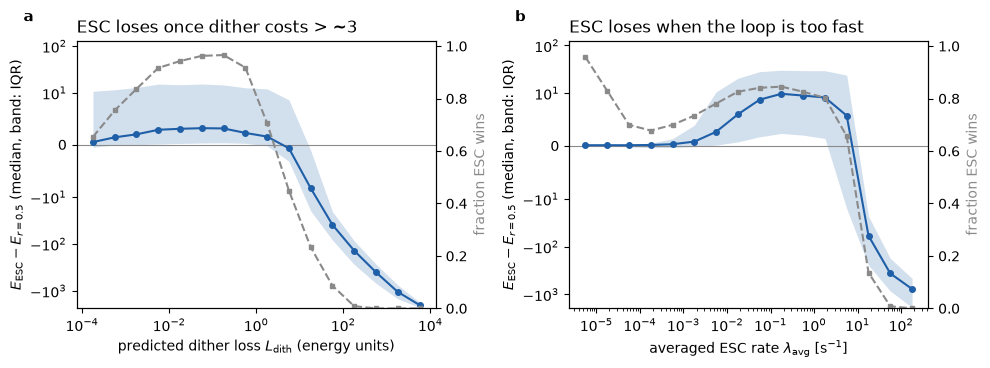

All runs: ESC wins 0.749
Well-tuned runs (0.1 < lam_avg < 3, L_dith < 1): 31998 (16.0%), ESC wins 0.935, median gain 12.17


In [ ]:
# ESC vs fixed r = 0.5: effect of dither loss and averaged rate (report Fig. 6a)
d = df.copy()
d['dE'] = d['energy_ESC'] - d['energy_const']
d['L'] = dither_loss(d['dither_amplitude'], d['dither_frequency'])
d['lam'] = lam_avg(d['optimizer_gain'], d['dither_frequency'])

def by_bins(col, edges):
    g = d.groupby(pd.cut(np.log10(d[col]), edges), observed=True)
    mid = 10 ** np.array([(iv.left + iv.right) / 2 for iv in g.size().index])
    return mid, g

with plt.style.context('default'):
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
    for ax, col, edges, xlabel, title in [
            (axs[0], 'L', np.arange(-4, 4.01, 0.5), r'predicted dither loss $L_\mathrm{dith}$ (energy units)',
             'ESC loses once dither costs > ~3'),
            (axs[1], 'lam', np.arange(-7, 2.51, 0.5), r'averaged ESC rate $\lambda_\mathrm{avg}$ [s$^{-1}$]',
             'ESC loses when the loop is too fast')]:
        mid, g = by_bins(col, edges)
        ax.axhline(0, color=GR, lw=0.8)
        ax.fill_between(mid, g['dE'].quantile(0.25), g['dE'].quantile(0.75), color=FOC, alpha=0.2, lw=0)
        ax.plot(mid, g['dE'].median(), 'o-', color=FOC, ms=4)
        ax.set_xscale('log'); ax.set_yscale('symlog', linthresh=10)
        ax.set_xlabel(xlabel); ax.set_ylabel(r'$E_\mathrm{ESC}-E_{r=0.5}$ (median, band: IQR)')
        ax2 = ax.twinx()
        ax2.plot(mid, g['choose_ESC'].mean(), 's--', color=GR, ms=3.5)
        ax2.set_ylim(0, 1.02); ax2.set_ylabel('fraction ESC wins', color=GR)
        ax.set_title(title, loc='left')
    for a_, l_ in zip(axs, 'ab'):
        panel_letter(a_, l_)
    fig.tight_layout()
    # fig.savefig('oto_energy_dither_rate.png', dpi=300, bbox_inches='tight')
    plt.show()

tuned = d[(d['lam'] > 0.1) & (d['lam'] < 3) & (d['L'] < 1)]
print(f"All runs: ESC wins {d['choose_ESC'].mean():.3f}")
print(f"Well-tuned runs (0.1 < lam_avg < 3, L_dith < 1): {len(tuned)} ({len(tuned)/len(d):.1%}), "
      f"ESC wins {tuned['choose_ESC'].mean():.3f}, median gain {tuned['dE'].median():.2f}")